# Módulo 05: Corrientes de Turbidez Submarinas (`sedmor.turbidity`)

Las corrientes de turbidez son flujos gravitacionales impulsados por la diferencia de densidad $\Delta\rho$ que genera el sedimento en suspensión respecto al agua ambiental. Su dinámica presenta dos regímenes opuestos: **autoaceleración** (*ignition*) cuando la pendiente permite erosionar más lecho, o **disipación/deposición** cuando el talud disminuye hacia la llanura abisal.

### Objetivos de aprendizaje
1. Simular corrientes de turbidez cohesivas (`turbidity_current_mud`) sobre un talud constante y sobre un perfil cóncavo de cañón submarino con pendiente variable.
2. Analizar la evolución del espesor $h_2(s)$, velocidad media $v_2(s)$, concentración $c_2(s)$ y número de Richardson $Ri(s)$ en una corriente de turbidez arenosa (`turbidity_current_sand`).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sedmor as sm

plt.rcParams["figure.dpi"] = 110
print(f"Librería sedmor v{sm.__version__} cargada.")


Librería sedmor v0.1.0 cargada.


## 1. Corriente de Turbidez de Fango: Talud Constante vs Cañón Submarino

Definimos un perfil longitudinal de cañón donde la pendiente pasa de $2.5^\circ$ en la zona alta a $0.15^\circ$ en el abanico submarino, y lo comparamos con un talud constante de $0.8^\circ$.


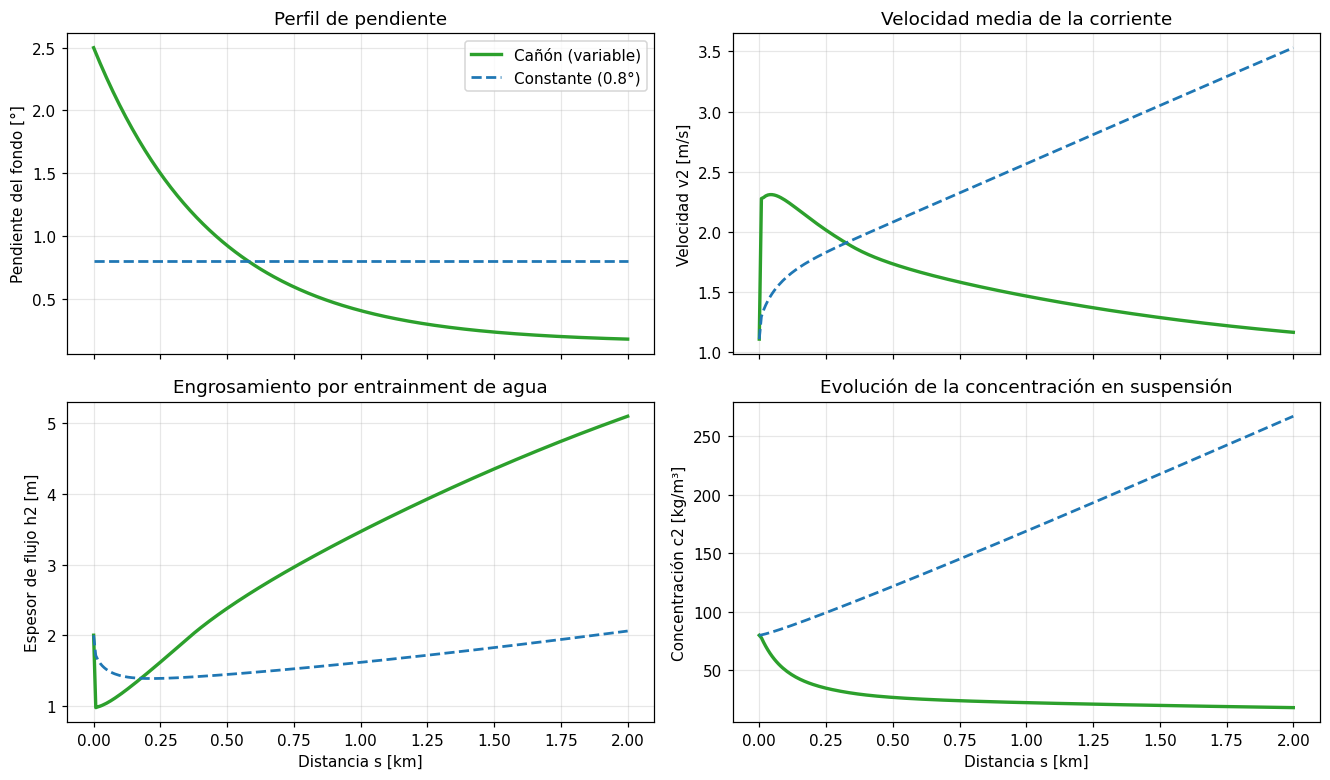

In [2]:
s_grid = np.linspace(0.0, 2000.0, 250)  # distancia en m

res_const = sm.turbidity.turbidity_current_mud(
    slope_deg=0.8, s=s_grid, h20=2.0, c20=80.0, fr20=1.15, mode="constant"
)

def slope_canyon(s_val: float) -> float:
    return float(0.15 + 2.35 * np.exp(-s_val / 450.0))

res_var = sm.turbidity.turbidity_current_mud(
    slope_deg=slope_canyon, s=s_grid, h20=2.0, c20=80.0, fr20=1.15, mode="varying"
)

fig, axes = plt.subplots(2, 2, figsize=(12.2, 7.2), sharex=True)

axes[0, 0].plot(res_var.s / 1000.0, res_var.slope_deg, lw=2.2, color="tab:green", label="Cañón (variable)")
axes[0, 0].plot(res_const.s / 1000.0, res_const.slope_deg, "--", lw=1.8, color="tab:blue", label="Constante (0.8°)")
axes[0, 0].set_ylabel("Pendiente del fondo [°]")
axes[0, 0].set_title("Perfil de pendiente")
axes[0, 0].grid(alpha=0.3)
axes[0, 0].legend()

axes[0, 1].plot(res_var.s / 1000.0, res_var.v2, lw=2.2, color="tab:green", label="Cañón (variable)")
axes[0, 1].plot(res_const.s / 1000.0, res_const.v2, "--", lw=1.8, color="tab:blue", label="Constante")
axes[0, 1].set_ylabel("Velocidad v2 [m/s]")
axes[0, 1].set_title("Velocidad media de la corriente")
axes[0, 1].grid(alpha=0.3)

axes[1, 0].plot(res_var.s / 1000.0, res_var.h2, lw=2.2, color="tab:green")
axes[1, 0].plot(res_const.s / 1000.0, res_const.h2, "--", lw=1.8, color="tab:blue")
axes[1, 0].set_xlabel("Distancia s [km]")
axes[1, 0].set_ylabel("Espesor de flujo h2 [m]")
axes[1, 0].set_title("Engrosamiento por entrainment de agua")
axes[1, 0].grid(alpha=0.3)

axes[1, 1].plot(res_var.s / 1000.0, res_var.c2_mass, lw=2.2, color="tab:green")
axes[1, 1].plot(res_const.s / 1000.0, res_const.c2_mass, "--", lw=1.8, color="tab:blue")
axes[1, 1].set_xlabel("Distancia s [km]")
axes[1, 1].set_ylabel("Concentración c2 [kg/m³]")
axes[1, 1].set_title("Evolución de la concentración en suspensión")
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 2. Corriente de Turbidez Arenosa en Talud Pronunciado

Simulamos una corriente de arena fina ($d_{50} = 0.12\,\text{mm}$) descargando en un talud empinado ($8^\circ$ inicialmente que se suaviza a $2^\circ$) mediante `turbidity_current_sand`.


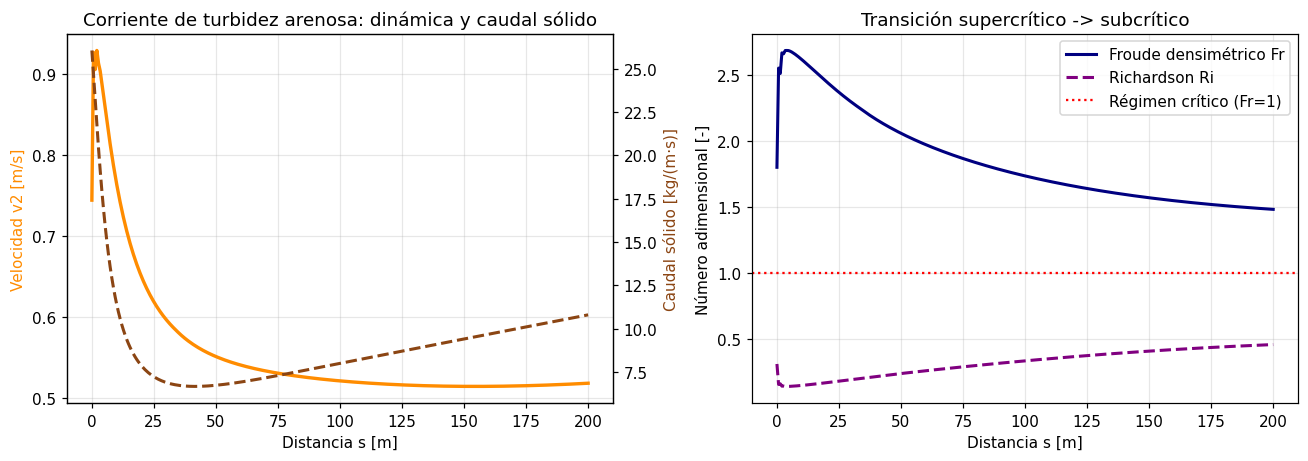

In [3]:
s_sand = np.linspace(0.0, 200.0, 300)
slopes_sand = 2.0 + 6.0 * np.exp(-s_sand / 60.0)

res_sand = sm.turbidity.turbidity_current_sand(
    slope_deg=slopes_sand, s=s_sand, d50=0.00012, wso=0.010, h20=0.10, c20=350.0, fr20=1.8
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))

ax1.plot(res_sand.s, res_sand.v2, lw=2.2, color="darkorange", label="Velocidad v2 [m/s]")
ax1.set_xlabel("Distancia s [m]")
ax1.set_ylabel("Velocidad v2 [m/s]", color="darkorange")
ax1_r = ax1.twinx()
ax1_r.plot(res_sand.s, res_sand.qs_mass, "--", lw=2, color="saddlebrown", label="Caudal sólido qs [kg/(m·s)]")
ax1_r.set_ylabel("Caudal sólido [kg/(m·s)]", color="saddlebrown")
ax1.set_title("Corriente de turbidez arenosa: dinámica y caudal sólido")
ax1.grid(alpha=0.3)

ax2.plot(res_sand.s, res_sand.froude, lw=2.0, color="navy", label="Froude densimétrico Fr")
ax2.plot(res_sand.s, res_sand.richardson, "--", lw=2.0, color="purple", label="Richardson Ri")
ax2.axhline(1.0, color="red", ls=":", label="Régimen crítico (Fr=1)")
ax2.set_xlabel("Distancia s [m]")
ax2.set_ylabel("Número adimensional [-]")
ax2.set_title("Transición supercrítico -> subcrítico")
ax2.grid(alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


### Ejercicios propuestos
1. Busque el ángulo mínimo de pendiente constante en `turbidity_current_mud` que mantiene una velocidad estacionaria sin extinción del flujo.
2. Analice el impacto de aumentar el tamaño de arena `d50` a `0.25 mm` (y su velocidad de caída `wso`) en el alcance longitudinal de la corriente arenosa.
